In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from tqdm.auto import tqdm
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
Device: cuda
GPU: Tesla T4


In [2]:

transform = transforms.ToTensor()

train_full = datasets.MNIST(
    root="/kaggle/working/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="/kaggle/working/data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_full))
print("Test samples:", len(test_dataset))

image, label = train_full[0]

print("Image shape:", image.shape)
print("Label:", label)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.09MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.11MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.16MB/s]

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])
Label: 5


In [3]:
train_dataset, val_dataset = random_split(
    train_full,
    [50000, 10000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 50000
Validation: 10000
Test: 10000


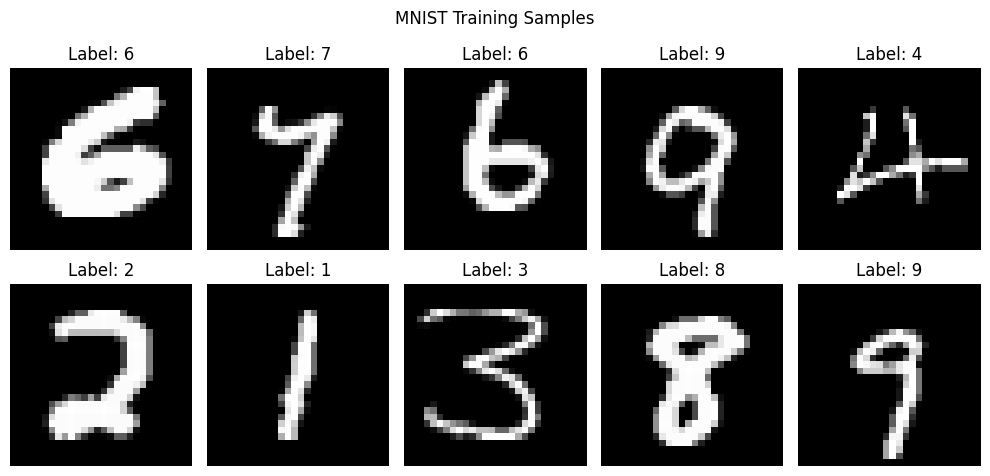

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("MNIST Training Samples")
plt.tight_layout()
plt.show()


### Training loop

In [5]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        
        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * labels.size(0)
        
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size
    return total_loss / total, correct / total

In [6]:
def fit(model, train_loader, val_loader, epochs=10, lr=0.001, device="cuda", model_name="model"):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    start_time = time.time()

    for epoch in tqdm(range(epochs), desc=f"Training {model_name}", leave=True):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            
        training_time = time.time() - start_time
        
    model.load_state_dict(best_weights)
    torch.save(
        model.state_dict(),
        f"/kaggle/working/{model_name}_best.pth"
    )

    return model, history, training_time

In [7]:
@torch.no_grad()
def evaluate(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total

### Softmax

In [8]:
class Softmaxclassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 10),
        )
    def forward(self, x):
        logits = self.fc(x)
        return logits


softmax_model = Softmaxclassifier().to(device)
softmax_model, softmax_history, softmax_time = fit(
    model=softmax_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    device=device,
    model_name="softmax"
)

Training softmax:   0%|          | 0/10 [00:00<?, ?it/s]

### MLP

In [9]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )
    def forward(self, x):
        logits = self.network(x)
        return logits

mlp_model = MLPClassifier()
mlp_model, mlp_history, mlp_time = fit(
    model=mlp_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    device=device,
    model_name="mlp"
)

Training mlp:   0%|          | 0/10 [00:00<?, ?it/s]

### CNN

In [10]:
class CNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32*7*7,128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,10),
        )
    def forward(self, x):
        features = self.features(x)
        logits = self.classifier(features)
        return logits

cnn_model = CNNClassifier()
cnn_model, cnn_history, cnn_time = fit(
    model=cnn_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    device=device,
    model_name="cnn"
)

Training cnn:   0%|          | 0/10 [00:00<?, ?it/s]

### Evaluate

In [11]:
criterion = nn.CrossEntropyLoss()

models = {
    "Softmax": softmax_model,
    "MLP": mlp_model,
    "CNN": cnn_model
}

training_times = {
    "Softmax": softmax_time,
    "MLP": mlp_time,
    "CNN": cnn_time
}

for name, model in models.items():
    test_loss, test_acc = evaluate(
        model, test_loader, criterion, device
    )

    params = sum(
        p.numel() for p in model.parameters()
    )

    train_time = training_times[name]

    print(
        f"{name:10s} | "
        f"Accuracy: {test_acc*100:.2f}% | "
        f"Parameters: {params:,} | "
        f"Training Time: {train_time:.2f}s"
    )

Softmax    | Accuracy: 92.51% | Parameters: 7,850 | Training Time: 61.97s
MLP        | Accuracy: 97.24% | Parameters: 109,386 | Training Time: 63.67s
CNN        | Accuracy: 98.90% | Parameters: 214,538 | Training Time: 70.94s


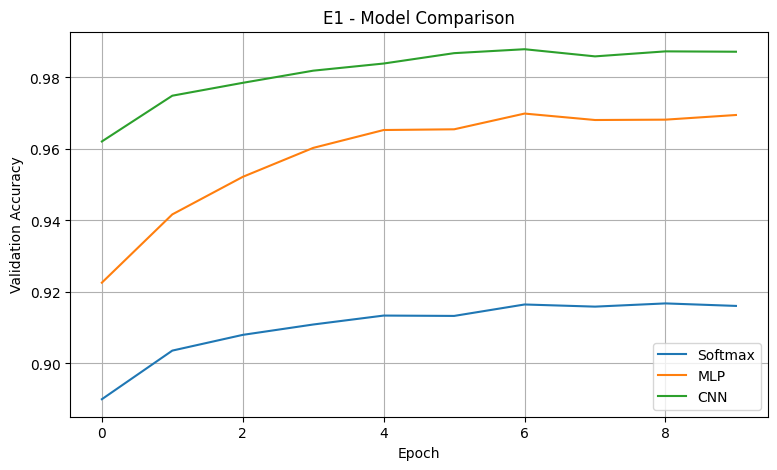

In [12]:
import matplotlib.pyplot as plt

histories = {
    "Softmax": softmax_history,
    "MLP": mlp_history,
    "CNN": cnn_history
}

plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(
        history["val_acc"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("E1 - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

### Trường hợp sai

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

@torch.no_grad()
def plot_confusion_matrix(model, test_loader, device, model_name):
    model.eval()

    all_labels = []
    all_preds = []

    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

    cm = confusion_matrix(
        all_labels,
        all_preds,
        labels=list(range(10))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(range(10))
    )

    fig, ax = plt.subplots(figsize=(8, 7))
    disp.plot(ax=ax, cmap="Blues", values_format="d")

    ax.set_title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return np.array(all_labels), np.array(all_preds)

In [14]:
@torch.no_grad()
def show_misclassified(model, test_loader, device, model_name, n=10):
    model.eval()

    wrong_images = []
    wrong_labels = []
    wrong_preds = []
    wrong_probs = []

    for images, labels in test_loader:
        images_gpu = images.to(device)

        logits = model(images_gpu)
        probabilities = torch.softmax(logits, dim=1)

        predictions = probabilities.argmax(dim=1)
        confidence = probabilities.max(dim=1).values

        wrong_mask = predictions.cpu() != labels

        wrong_images.extend(images[wrong_mask])
        wrong_labels.extend(labels[wrong_mask].tolist())
        wrong_preds.extend(
            predictions.cpu()[wrong_mask].tolist()
        )
        wrong_probs.extend(
            confidence.cpu()[wrong_mask].tolist()
        )

    n = min(n, len(wrong_images))

    if n == 0:
        print(f"{model_name}: No misclassified images!")
        return

    fig, axes = plt.subplots(
        2, 5,
        figsize=(16, 8)
    )
    
    for i, ax in enumerate(axes.flat):
        if i < n:
            ax.imshow(wrong_images[i].squeeze(), cmap="gray")
    
            ax.set_title(
                f"True: {wrong_labels[i]} | Pred: {wrong_preds[i]}\n"
                f"Confidence: {wrong_probs[i]*100:.1f}%",
                fontsize=11,
                pad=12
            )
    
        ax.axis("off")
    
    plt.suptitle(
        f"{model_name} - Misclassified Images",
        fontsize=16,
        y=0.98
    )
    
    plt.subplots_adjust(
        hspace=0.65,  
        wspace=0.20,  
        top=0.85
    )
    
    plt.show()

    print(f"Total misclassified images: {len(wrong_images)}")


Model: Softmax


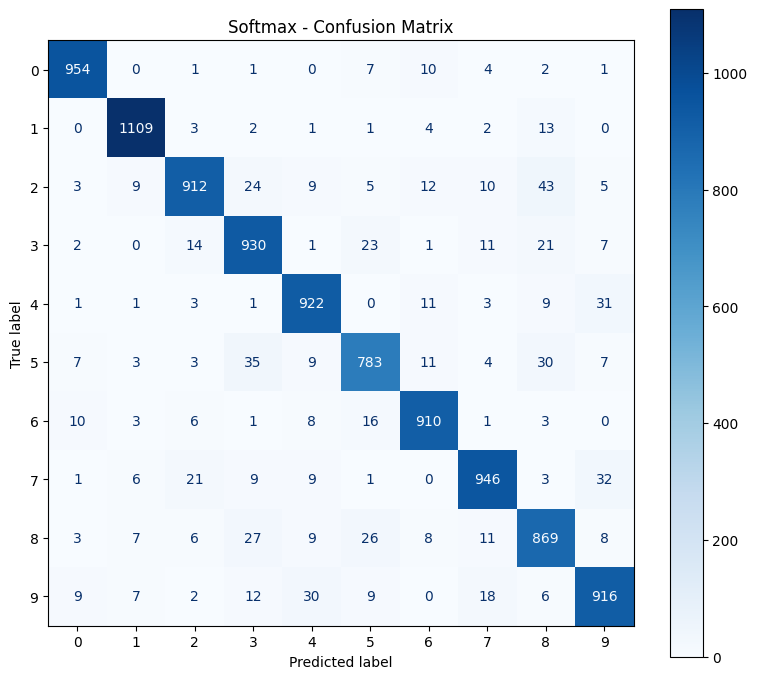

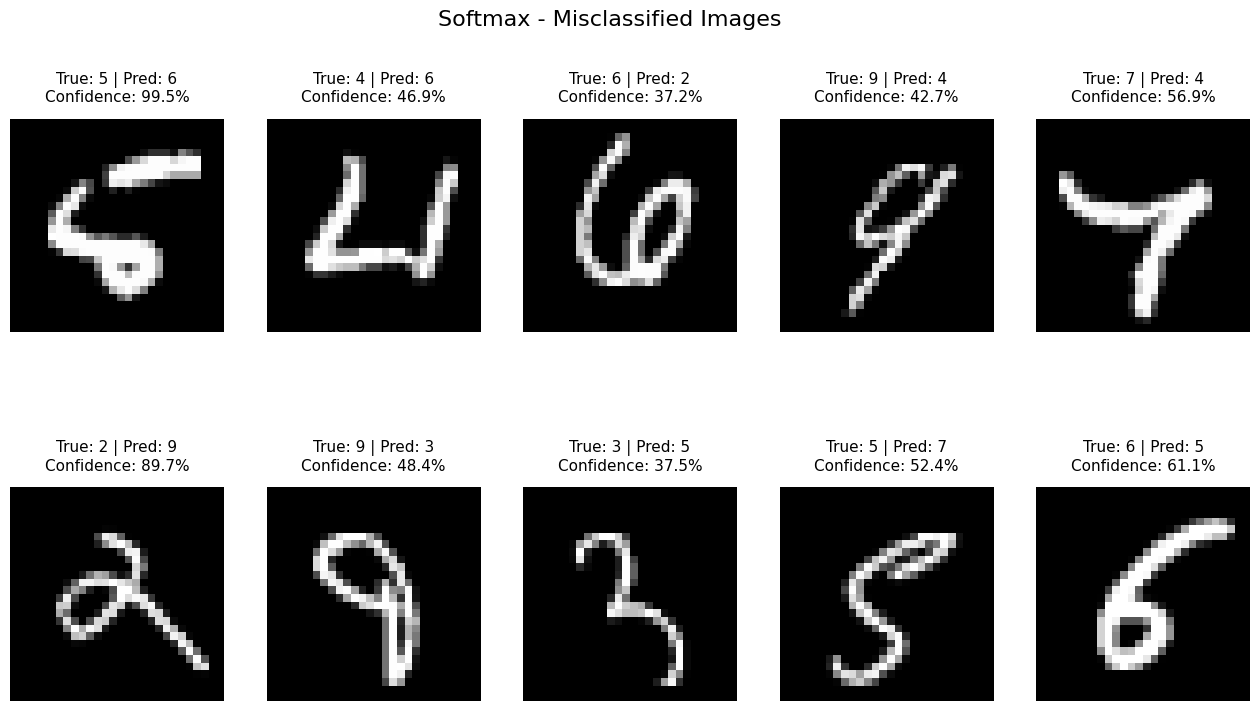

Total misclassified images: 749

Model: MLP


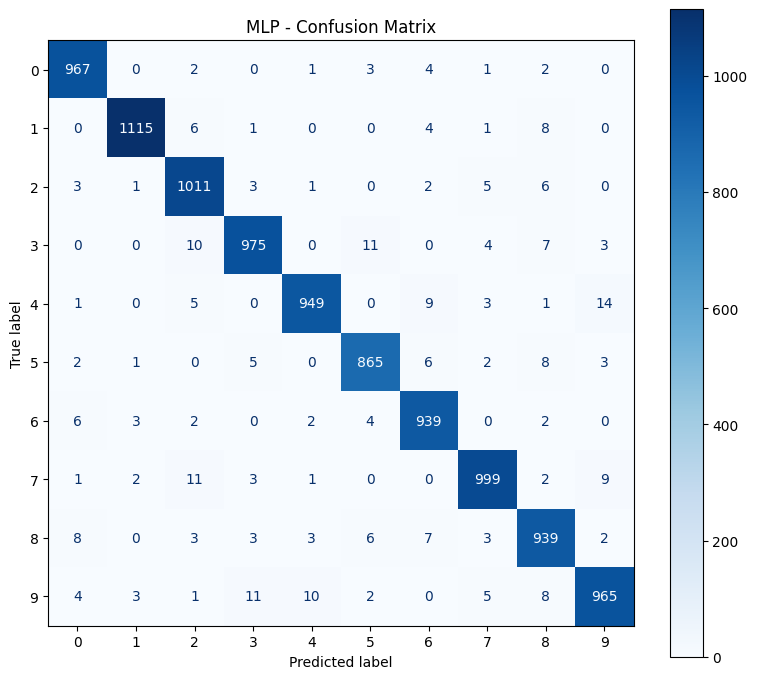

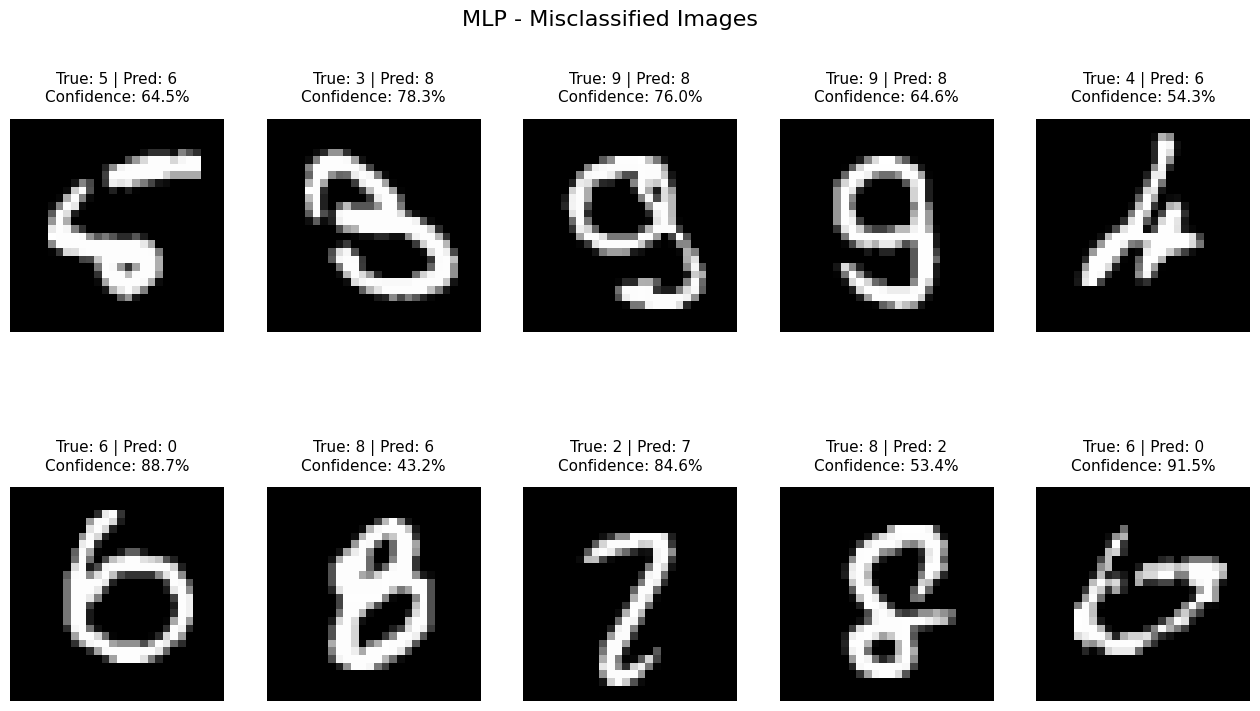

Total misclassified images: 276

Model: CNN


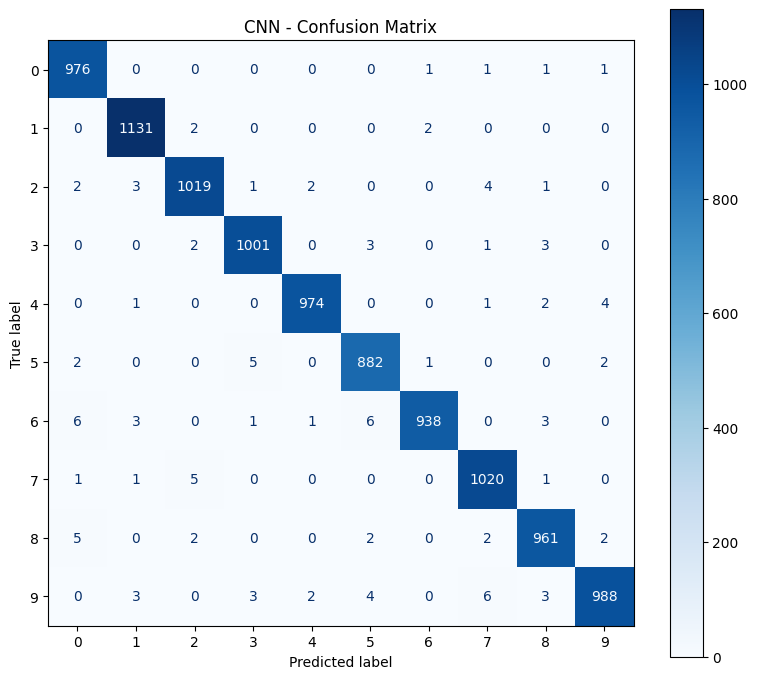

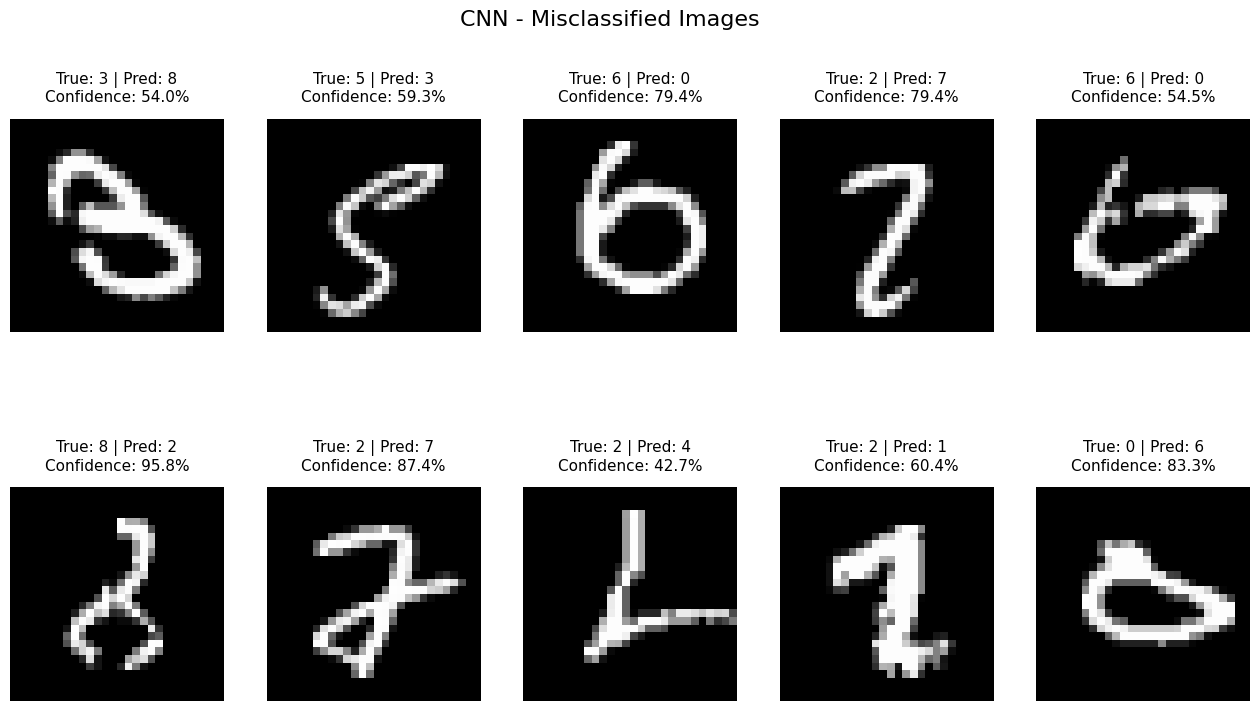

Total misclassified images: 110


In [15]:
models = {
    "Softmax": softmax_model,
    "MLP": mlp_model,
    "CNN": cnn_model
}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Model: {name}")
    print(f"{'='*50}")

    # 1. Confusion Matrix
    true_labels, pred_labels = plot_confusion_matrix(
        model,
        test_loader,
        device,
        name
    )

    # 2. Misclassified Images
    show_misclassified(
        model,
        test_loader,
        device,
        name,
        n=10
    )